In [14]:
import os, cv2, numpy as np, pandas as pd
from pathlib import Path
from collections import defaultdict
import random

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

from sklearn.metrics import balanced_accuracy_score, confusion_matrix, jaccard_score, f1_score
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
print(f"CUDA available: {torch.cuda.is_available()}")

CUDA available: True


In [15]:
import os

class ConfigSegmentation:
    TARGET_SIZE = 512
    NUM_CLASSES = 2
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    WEIGHTS_PATH = "/kaggle/input/model-weights/weights/2a"
    DETECTION_THRESHOLD = 0.6

class ConfigClassification:
    TARGET_SIZE = 224
    NUM_CLASSES = 2
    MASK_DILATION_PX = 5
    GRAY_BACKGROUND = 0  # Match training (black background)
    N_FOLDS = 5
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    WEIGHTS_PATH = "/kaggle/input/model-weights/weights/2b"

# Data paths
INPUT_DIRECTORY = '/kaggle/input/breast-lesions/'
TEST_IMG_DIRECTORY = Path(INPUT_DIRECTORY) / 'test' / 'images'
TEST_LABELS_PATH = INPUT_DIRECTORY + 'test/test_metadata.xlsx'
TRAIN_LABELS_PATH = INPUT_DIRECTORY + 'train/train_metadata.xlsx'

print(f"Segmentation config:")
print(f"  Target size: {ConfigSegmentation.TARGET_SIZE}")
print(f"  Weights path: {ConfigSegmentation.WEIGHTS_PATH}")
print(f"\nClassification config:")
print(f"  Target size: {ConfigClassification.TARGET_SIZE}")
print(f"  Gray background: {ConfigClassification.GRAY_BACKGROUND}")
print(f"  Weights path: {ConfigClassification.WEIGHTS_PATH}")

Segmentation config:
  Target size: 512
  Weights path: /kaggle/input/model-weights/weights/2a

Classification config:
  Target size: 224
  Gray background: 0
  Weights path: /kaggle/input/model-weights/weights/2b


## Preprocessing Functions (Identical to Training)

In [16]:
def resize_with_padding(img, mask=None, target_size=512):
    """Resize with padding to target size"""
    h, w = img.shape[:2]
    scale = target_size / max(h, w)
    new_h, new_w = int(h * scale), int(w * scale)
    
    img_resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_CUBIC)
    if mask is not None:
        mask_resized = cv2.resize(mask, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
    
    pad_h, pad_w = target_size - new_h, target_size - new_w
    pad_top, pad_left = pad_h // 2, pad_w // 2
    pad_bottom, pad_right = pad_h - pad_top, pad_w - pad_left
    
    img_padded = cv2.copyMakeBorder(img_resized, pad_top, pad_bottom, pad_left, pad_right, cv2.BORDER_CONSTANT, value=0)
    
    if mask is not None:
        mask_padded = cv2.copyMakeBorder(mask_resized, pad_top, pad_bottom, pad_left, pad_right, cv2.BORDER_CONSTANT, value=0)
        return img_padded, mask_padded, (pad_top, pad_left, new_h, new_w, h, w)
    return img_padded, (pad_top, pad_left, new_h, new_w, h, w)

def has_colors(img, sat_thresh=40, delta_thresh=20, white_brightness_thresh=200, white_sat_thresh=30, red_sat_thresh=50, blue_sat_thresh=50):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    b, g, r = cv2.split(img)
    r, g, b = r.astype(np.int16), g.astype(np.int16), b.astype(np.int16)
    
    delta = np.maximum.reduce([np.abs(r - g), np.abs(r - b), np.abs(g - b)])
    mask = np.logical_or.reduce([
        np.logical_and(delta > delta_thresh, s > sat_thresh),
        (s < white_sat_thresh) & (v > white_brightness_thresh),
        ((h < 15) | (h > 165)) & (s > red_sat_thresh),
        ((h >= 100) & (h <= 130)) & (s > blue_sat_thresh)
    ]).astype(np.uint8) * 255
    
    return np.sum(mask) > 0, mask

def inpaint(img):
    detected, mask = has_colors(img)
    return cv2.inpaint(img, mask, 3, cv2.INPAINT_TELEA) if detected else img

def apply_median_filter(image, kernel_size=5):
    return cv2.medianBlur(image.astype(np.uint8), kernel_size)

def apply_clahe(image, clip_limit=2.0, tile_grid_size=(8, 8)):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    return clahe.apply(image)

def apply_zscore_normalization(image):
    image = image.astype(np.float32)
    mean, std = np.mean(image), np.std(image)
    return (image - mean) / std if std > 0 else image - mean

print("✅ Preprocessing functions loaded")

✅ Preprocessing functions loaded


In [17]:
!pip install timm transformers segmentation-models-pytorch ranger21 -q

import timm
from transformers import SegformerForSemanticSegmentation
from ranger21 import Ranger21

print("✅ Dependencies installed")

✅ Dependencies installed


In [18]:
class ContourAwareDecoder(nn.Module):
    def __init__(self, in_channels_list=[64, 128, 320, 512]):
        super().__init__()
        self.projections = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(c, 64, 1),
                nn.BatchNorm2d(64),
                nn.ReLU(inplace=True)
            ) for c in in_channels_list
        ])
        self.fusion = nn.Sequential(
            nn.Conv2d(64 * 4, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        self.contour_head = nn.Conv2d(64, 1, 1)
    
    def forward(self, hidden_states, target_size):
        projected = []
        for proj, h in zip(self.projections, hidden_states):
            p = proj(h)
            p = F.interpolate(p, size=target_size, mode='bilinear', align_corners=False)
            projected.append(p)
        fused = torch.cat(projected, dim=1)
        fused = self.fusion(fused)
        return self.contour_head(fused)


class DualHeadSegFormerDeepSup(nn.Module):
    def __init__(self, num_classes=2, model_name="nvidia/segformer-b2-finetuned-ade-512-512"):
        super().__init__()
        self.segformer = SegformerForSemanticSegmentation.from_pretrained(
            model_name, num_labels=num_classes, ignore_mismatched_sizes=True
        )
        original_conv = self.segformer.segformer.encoder.patch_embeddings[0].proj
        self.segformer.segformer.encoder.patch_embeddings[0].proj = nn.Conv2d(
            1, original_conv.out_channels, kernel_size=original_conv.kernel_size,
            stride=original_conv.stride, padding=original_conv.padding
        )
        self.segformer.segformer.encoder.patch_embeddings[0].proj.weight.data = \
            original_conv.weight.data.mean(dim=1, keepdim=True)
        
        self.aux_heads = nn.ModuleList([
            nn.Conv2d(64, num_classes, 1),
            nn.Conv2d(128, num_classes, 1),
            nn.Conv2d(320, num_classes, 1),
        ])
        self.contour_decoder = ContourAwareDecoder(in_channels_list=[64, 128, 320, 512])
        self.detection_head = nn.Sequential(
            nn.Linear(num_classes, 128), nn.ReLU(inplace=True),
            nn.Dropout(0.3), 
            nn.Linear(128, 64), nn.ReLU(inplace=True),
            nn.Linear(64, 2)
        )
    
    def forward(self, x):
        encoder_outputs = self.segformer.segformer.encoder(
            x, output_hidden_states=True, return_dict=True
        )
        hidden_states = encoder_outputs.hidden_states
        main_logits = self.segformer.decode_head(hidden_states)
        main_logits = F.interpolate(main_logits, size=x.shape[2:], mode='bilinear', align_corners=False)
        global_features = F.adaptive_avg_pool2d(main_logits, (1, 1)).squeeze(-1).squeeze(-1)
        detection_logits = self.detection_head(global_features)
        return detection_logits, main_logits

print("✅ Segmentation models defined")

✅ Segmentation models defined


In [19]:
class MultiHeadSpatialAttention(nn.Module):
    def __init__(self, in_channels, num_heads=3):
        super().__init__()
        self.num_heads = num_heads
        kernel_sizes = [3, 5, 7]
        self.attentions = nn.ModuleList([
            nn.Conv2d(2, 1, ks, padding=ks//2, bias=False) for ks in kernel_sizes
        ])
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        combined = torch.cat([avg_out, max_out], dim=1)
        att_maps = [self.sigmoid(att(combined)) for att in self.attentions]
        final_att = torch.mean(torch.stack(att_maps), dim=0)
        return x * final_att


class EdgeAwareModule(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()
        self.register_buffer('sobel_x', torch.tensor([
            [-1., 0., 1.],
            [-2., 0., 2.],
            [-1., 0., 1.]
        ]).unsqueeze(0).unsqueeze(0))
        self.register_buffer('sobel_y', torch.tensor([
            [-1., -2., -1.],
            [0., 0., 0.],
            [1., 2., 1.]
        ]).unsqueeze(0).unsqueeze(0))
        self.edge_processor = nn.Sequential(
            nn.Conv2d(2, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1)
        )
    
    def forward(self, x):
        x_gray = x.mean(dim=1, keepdim=True) if x.shape[1] == 3 else x
        edges_x = F.conv2d(x_gray, self.sobel_x, padding=1)
        edges_y = F.conv2d(x_gray, self.sobel_y, padding=1)
        edges = torch.cat([edges_x, edges_y], dim=1)
        edge_features = self.edge_processor(edges)
        return edge_features.flatten(1)


class ROIFocusedAttention(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.channel_att = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, in_channels//16, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels//16, in_channels, 1),
            nn.Sigmoid()
        )
        self.multi_head_spatial = MultiHeadSpatialAttention(in_channels, num_heads=3)
    
    def forward(self, x):
        ca = self.channel_att(x)
        x = x * ca
        x = self.multi_head_spatial(x)
        return x


class EfficientNetWithROIAwareCBAM(nn.Module):
    def __init__(self, num_classes=2, dropout=0.6, pretrained=True):
        super().__init__()
        
        self.backbone = timm.create_model(
            'efficientnet_b3',
            pretrained=pretrained,
            num_classes=0,
            global_pool=''
        )
        

        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            features = self.backbone(dummy)
            features_dim = features.shape[1]
        
        self.roi_attention = ROIFocusedAttention(features_dim)
        
        self.edge_module = EdgeAwareModule(in_channels=3)
        edge_feature_dim = 64
        
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        
        fusion_dim = features_dim + edge_feature_dim
        self.fusion_layer = nn.Sequential(
            nn.Linear(fusion_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout)
        )
        
        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )
        
        self.aux_classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )
    
    def forward(self, x, return_aux=False):
        spatial_features = self.backbone(x)
        spatial_features = self.roi_attention(spatial_features)
        
        spatial_pooled = self.global_pool(spatial_features)
        spatial_pooled = spatial_pooled.flatten(1)
        
        edge_features = self.edge_module(x)
        
        fused = torch.cat([spatial_pooled, edge_features], dim=1)
        fused = self.fusion_layer(fused)
        
        main_logits = self.classifier(fused)
        
        if return_aux:
            aux_logits = self.aux_classifier(fused)
            return main_logits, aux_logits
        
        return main_logits

print("✅ Classification models defined (V6 - matching task2b-classification-v6.ipynb)")

✅ Classification models defined (V6 - matching task2b-classification-v6.ipynb)


In [20]:
def create_masked_image(image, mask, dilation_px=5, gray_value=0):
    if dilation_px > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (dilation_px*2+1, dilation_px*2+1))
        mask_dilated = cv2.dilate(mask, kernel, iterations=1)
    else:
        mask_dilated = mask.copy()
    
    masked_image = np.full_like(image, gray_value, dtype=np.uint8)
    mask_bool = mask_dilated > 127
    masked_image[mask_bool] = image[mask_bool]
    
    return masked_image, mask_dilated

def get_bbox_crop(image, mask, target_size=224, gray_bg=0):
    coords = np.where(mask > 0)
    if len(coords[0]) == 0:
        return np.full((target_size, target_size), gray_bg, dtype=np.float32)
    
    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()
    
    cropped = image[y_min:y_max+1, x_min:x_max+1].copy()
    
    h, w = cropped.shape
    if h == 0 or w == 0:
        return np.full((target_size, target_size), gray_bg, dtype=np.float32)
    
    scale = target_size / max(h, w)
    new_h, new_w = int(h * scale), int(w * scale)
    new_h, new_w = max(1, new_h), max(1, new_w)
    
    cropped_resized = cv2.resize(cropped, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    
    output = np.full((target_size, target_size), gray_bg, dtype=np.float32)
    pad_h = (target_size - new_h) // 2
    pad_w = (target_size - new_w) // 2
    output[pad_h:pad_h+new_h, pad_w:pad_w+new_w] = cropped_resized
    
    return output

print("✅ Classification preprocessing functions loaded")

✅ Classification preprocessing functions loaded


In [21]:
def load_patient_data(csv_path, images_dir):
    df = pd.read_excel(csv_path)
    patients_dict = defaultdict(list)
    
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Loading patient data"):
        img_name, mask_name, label = row['US'], row['MASK'], row['LABEL']
        patient_id = Path(img_name).stem.split('_')[0]
        
        patients_dict[patient_id].append({
            'img_path': str(Path(images_dir) / img_name),
            'mask_path': str(Path(images_dir) / mask_name),
            'img_name': img_name,
            'mask_name': mask_name,
            'label': label
        })
    
    patients = []
    for pid, samples in sorted(patients_dict.items(), key=lambda x: int(x[0])):
        labels = [s['label'] for s in samples]
        major_label = int(np.argmax(np.bincount(labels)))
        patients.append({
            'patient_id': pid,
            'samples': samples,
            'major_label': major_label
        })
    
    return patients

patients = load_patient_data(TEST_LABELS_PATH, Path(INPUT_DIRECTORY) / 'test' / 'images')

print(f"\n✅ Loaded {len(patients)} patients")
print(f"   Total images: {sum(len(p['samples']) for p in patients)}")
print(f"\n📋 Example patient structure:")
print(f"   Patient ID: {patients[0]['patient_id']}")
print(f"   Number of images: {len(patients[0]['samples'])}")
print(f"   Major label: {patients[0]['major_label']}")
print(f"   First image: {patients[0]['samples'][0]['img_name']}")

Loading patient data:   0%|          | 0/308 [00:00<?, ?it/s]


✅ Loaded 194 patients
   Total images: 308

📋 Example patient structure:
   Patient ID: 1
   Number of images: 1
   Major label: 2
   First image: 1.png


## Step 1: Segmentation Inference

In [22]:
seg_model = DualHeadSegFormerDeepSup(num_classes=2).to(ConfigSegmentation.DEVICE)
seg_model.eval()

seg_weights_dir = Path(ConfigSegmentation.WEIGHTS_PATH)
seg_weight_files = sorted(seg_weights_dir.glob('*.pt'))

if len(seg_weight_files) == 0:
    raise FileNotFoundError(f"❌ ERROR: No .pt files found in {ConfigSegmentation.WEIGHTS_PATH}")

weights_file = seg_weight_files[0]
try:
    checkpoint = torch.load(weights_file, map_location=ConfigSegmentation.DEVICE)
    if 'model_state_dict' in checkpoint:
        seg_model.load_state_dict(checkpoint['model_state_dict'], strict=False)
    else:
        seg_model.load_state_dict(checkpoint, strict=False)
    print(f"✅ Segmentation model loaded from {weights_file.name}")
except Exception as e:
    raise RuntimeError(f"❌ ERROR: Failed to load segmentation weights: {e}")

print(f"✅ Segmentation model ready\n")

print(f"{'='*80}")
print(f"🔬 SEGMENTATION INFERENCE")
print(f"{'='*80}\n")

total_images = sum(len(p['samples']) for p in patients)
processed = 0

for patient in tqdm(patients, desc="Processing patients"):
    for sample in patient['samples']:
        img_path = sample['img_path']
        
        img_bgr = cv2.imread(img_path)
        img_inpainted = inpaint(img_bgr)
        img_gray = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2GRAY)
        img_denoised = apply_median_filter(img_gray)
        img_resized, pad_info = resize_with_padding(img_denoised, None, ConfigSegmentation.TARGET_SIZE)
        img_clahe = apply_clahe(img_resized)
        img_normalized = apply_zscore_normalization(img_clahe)
        
        img_tensor = torch.from_numpy(img_normalized).unsqueeze(0).unsqueeze(0).float().to(ConfigSegmentation.DEVICE)
        
        with torch.no_grad():
            detection_logits, main_logits = seg_model(img_tensor)
            
            det_probs = F.softmax(detection_logits, dim=1)
            det_confidence = det_probs[0, 1].item()
            
            if det_confidence < ConfigSegmentation.DETECTION_THRESHOLD:
                pred_mask = np.zeros((ConfigSegmentation.TARGET_SIZE, ConfigSegmentation.TARGET_SIZE), dtype=np.uint8)
            else:
                pred_mask = torch.argmax(F.softmax(main_logits, dim=1), dim=1)[0].cpu().numpy().astype(np.uint8) * 255
        
        sample['pred_mask_512'] = pred_mask
        sample['det_confidence'] = det_confidence
        sample['has_roi'] = pred_mask.sum() > 0
        
        gt_mask = cv2.imread(sample['mask_path'], cv2.IMREAD_GRAYSCALE)
        sample['gt_mask'] = gt_mask
        
        processed += 1

print(f"\n{'='*80}")
print(f"✅ Segmentation complete:")
print(f"   Total images processed: {processed}")
print(f"   Images with ROI: {sum(1 for p in patients for s in p['samples'] if s['has_roi'])}")
print(f"{'='*80}\n")

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b2-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.weight: found shape torch.Size([150, 768, 1, 1]) in the checkpoint and torch.Size([2, 768, 1, 1]) in the model instantiated
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Segmentation model loaded from segformer_gating.pt
✅ Segmentation model ready

🔬 SEGMENTATION INFERENCE



Processing patients:   0%|          | 0/194 [00:00<?, ?it/s]


✅ Segmentation complete:
   Total images processed: 308
   Images with ROI: 205



## Visualize Segmentation Results

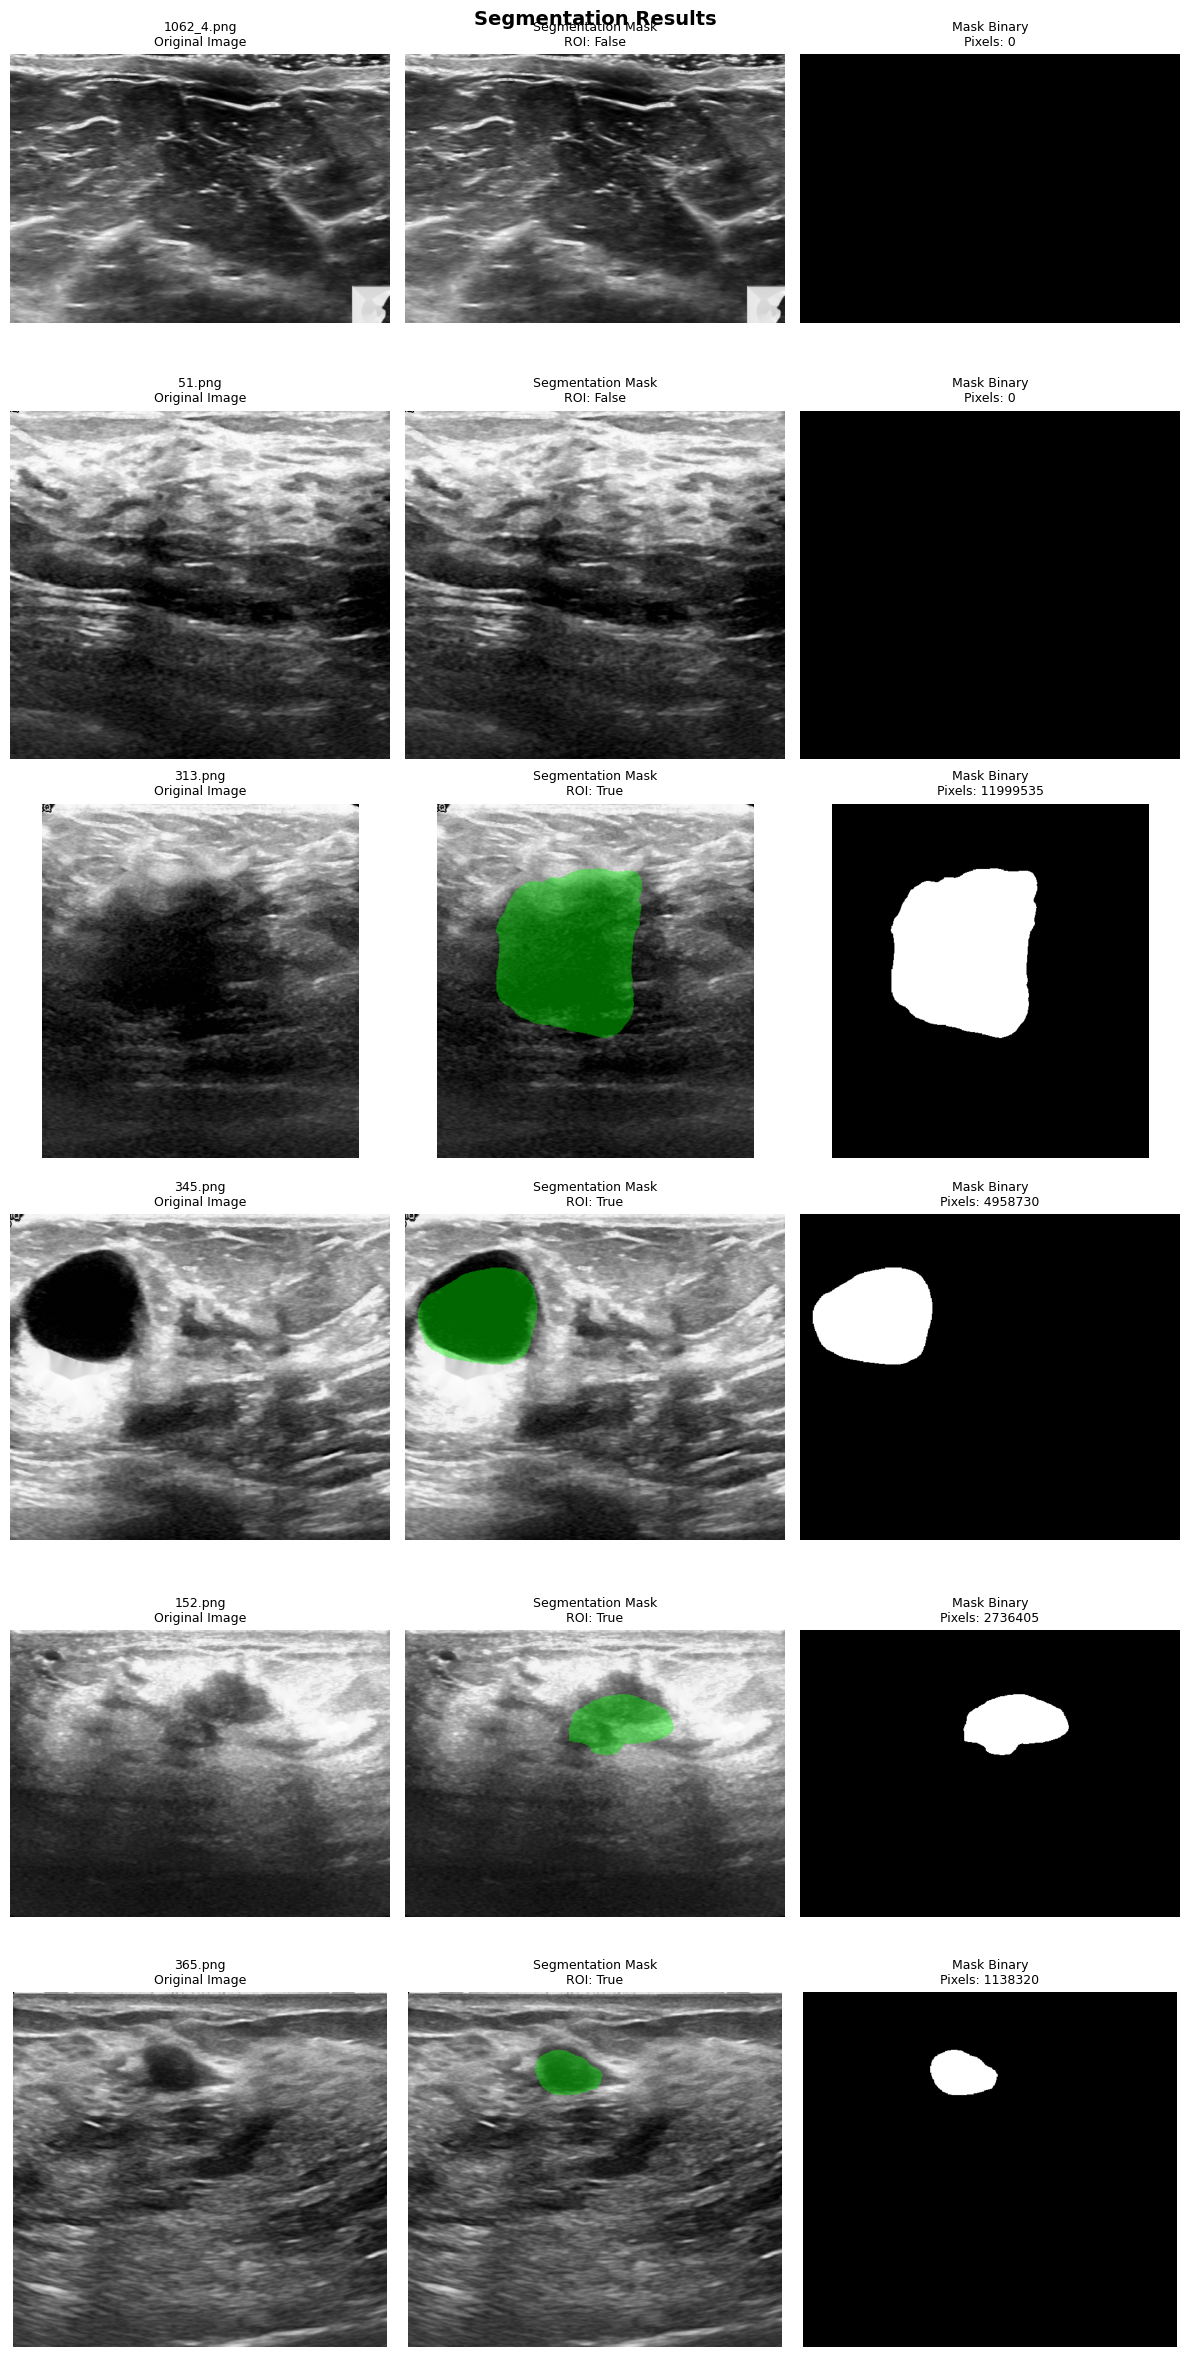


✅ Visualized 6 segmentation results


In [23]:
all_samples = [s for p in patients for s in p['samples']]
n_vis = min(6, len(all_samples))
indices_to_show = np.random.choice(len(all_samples), n_vis, replace=False)

fig, axes = plt.subplots(n_vis, 3, figsize=(12, 4*n_vis))
if n_vis == 1:
    axes = axes.reshape(1, -1)

for i, idx in enumerate(indices_to_show):
    sample = all_samples[idx]
    img_path = sample['img_path']
    
    img_bgr = cv2.imread(img_path)
    img_inpainted = inpaint(img_bgr)
    img_gray = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2GRAY)
    img_display = ((img_gray - img_gray.min()) / (img_gray.max() - img_gray.min() + 1e-8) * 255).astype(np.uint8)
    img_rgb = cv2.cvtColor(img_display, cv2.COLOR_GRAY2RGB)
    
    mask_512 = sample['pred_mask_512']
    h_orig, w_orig = img_gray.shape
    mask_orig_size = cv2.resize(mask_512, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
    
    axes[i, 0].imshow(img_display, cmap='gray')
    axes[i, 0].set_title(f'{Path(sample["img_name"]).name}\nOriginal Image', fontsize=9)
    axes[i, 0].axis('off')
    
    mask_overlay = img_rgb.copy()
    mask_overlay[mask_orig_size > 127] = [0, 255, 0]
    mask_overlay = cv2.addWeighted(img_rgb, 0.6, mask_overlay, 0.4, 0)
    axes[i, 1].imshow(mask_overlay)
    axes[i, 1].set_title(f'Segmentation Mask\nROI: {sample["has_roi"]}', fontsize=9)
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(mask_orig_size, cmap='gray')
    axes[i, 2].set_title(f'Mask Binary\nPixels: {mask_512.sum()}', fontsize=9)
    axes[i, 2].axis('off')

plt.suptitle('Segmentation Results', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n✅ Visualized {n_vis} segmentation results")

## Step 2: Classification Preprocessing

In [24]:
print(f"\n{'='*80}")
print(f"🔧 CLASSIFICATION PREPROCESSING")
print(f"{'='*80}\n")

processed_images = 0

for patient in tqdm(patients, desc="Classification Preprocessing"):
    for sample in patient['samples']:
        if not sample['has_roi']:
            sample['classification_input'] = None
            sample['pred_class'] = 2  # Normal
            continue
        
        # STEP 1: Load original image
        img_bgr = cv2.imread(sample['img_path'])
        
        # STEP 2: Classification preprocessing
        img_inpainted = inpaint(img_bgr)
        img_gray = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2GRAY)
        img_denoised = apply_median_filter(img_gray)
        img_clahe = apply_clahe(img_denoised)
        
        # Store for visualization
        sample['preprocessed'] = img_clahe.copy()
        
        
        # STEP 3: Get predicted mask (from segmentation) and resize to original size
        pred_mask_512 = sample['pred_mask_512']
        h_orig, w_orig = img_gray.shape
        pred_mask_resized = cv2.resize(pred_mask_512, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
        
        # STEP 4: Binarize mask (training uses > 0, masks are already 0 or 255)
        pred_mask_binary = (pred_mask_resized > 0).astype(np.uint8) * 255
        
        # STEP 5: Dilate for context
        if ConfigClassification.MASK_DILATION_PX > 0:
            kernel = cv2.getStructuringElement(
                cv2.MORPH_ELLIPSE,
                (ConfigClassification.MASK_DILATION_PX*2+1, ConfigClassification.MASK_DILATION_PX*2+1)
            )
            mask_dilated = cv2.dilate(pred_mask_binary, kernel, iterations=1)
        else:
            mask_dilated = pred_mask_binary.copy()
        
        # STEP 6: Create masked image (lesion only, rest black)
        masked_img = np.full_like(img_clahe, ConfigClassification.GRAY_BACKGROUND, dtype=np.uint8)
        mask_bool = mask_dilated > 0
        masked_img[mask_bool] = img_clahe[mask_bool]
        
        sample['masked'] = masked_img.copy()
        
        # STEP 5: Crop to bbox
        coords = np.where(mask_dilated > 0)
        if len(coords[0]) == 0:
            sample['classification_input'] = None
            sample['pred_class'] = 2
            continue
        
        y_min, y_max = coords[0].min(), coords[0].max()
        x_min, x_max = coords[1].min(), coords[1].max()
        cropped = masked_img[y_min:y_max+1, x_min:x_max+1].copy()
        
        h_crop, w_crop = cropped.shape
        if h_crop == 0 or w_crop == 0:
            sample['classification_input'] = None
            sample['pred_class'] = 2
            continue
        
        # STEP 6: Resize to 224x224 with padding
        scale = ConfigClassification.TARGET_SIZE / max(h_crop, w_crop)
        new_h, new_w = int(h_crop * scale), int(w_crop * scale)
        new_h, new_w = max(1, new_h), max(1, new_w)
        
        cropped_resized = cv2.resize(cropped, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
        
        output = np.full(
            (ConfigClassification.TARGET_SIZE, ConfigClassification.TARGET_SIZE),
            ConfigClassification.GRAY_BACKGROUND,
            dtype=np.float32
        )
        pad_h = (ConfigClassification.TARGET_SIZE - new_h) // 2
        pad_w = (ConfigClassification.TARGET_SIZE - new_w) // 2
        output[pad_h:pad_h+new_h, pad_w:pad_w+new_w] = cropped_resized.astype(np.float32)
        
        # STEP 7: Normalize to [0, 1]
        img_normalized = output / 255.0
        
        # STEP 8: Convert to 3-channel
        img_tensor = torch.from_numpy(img_normalized).float()
        img_tensor = img_tensor.unsqueeze(0).repeat(3, 1, 1)  # [3, 224, 224]
        
        sample['classification_input'] = img_tensor
        processed_images += 1

print(f"\n{'='*80}")
print(f"✅ Classification preprocessing complete")
print(f"   Images prepared for classification: {processed_images}")
print(f"{'='*80}\n")


🔧 CLASSIFICATION PREPROCESSING



Classification Preprocessing:   0%|          | 0/194 [00:00<?, ?it/s]


✅ Classification preprocessing complete
   Images prepared for classification: 205



## Visualize Classification Preprocessing Pipeline

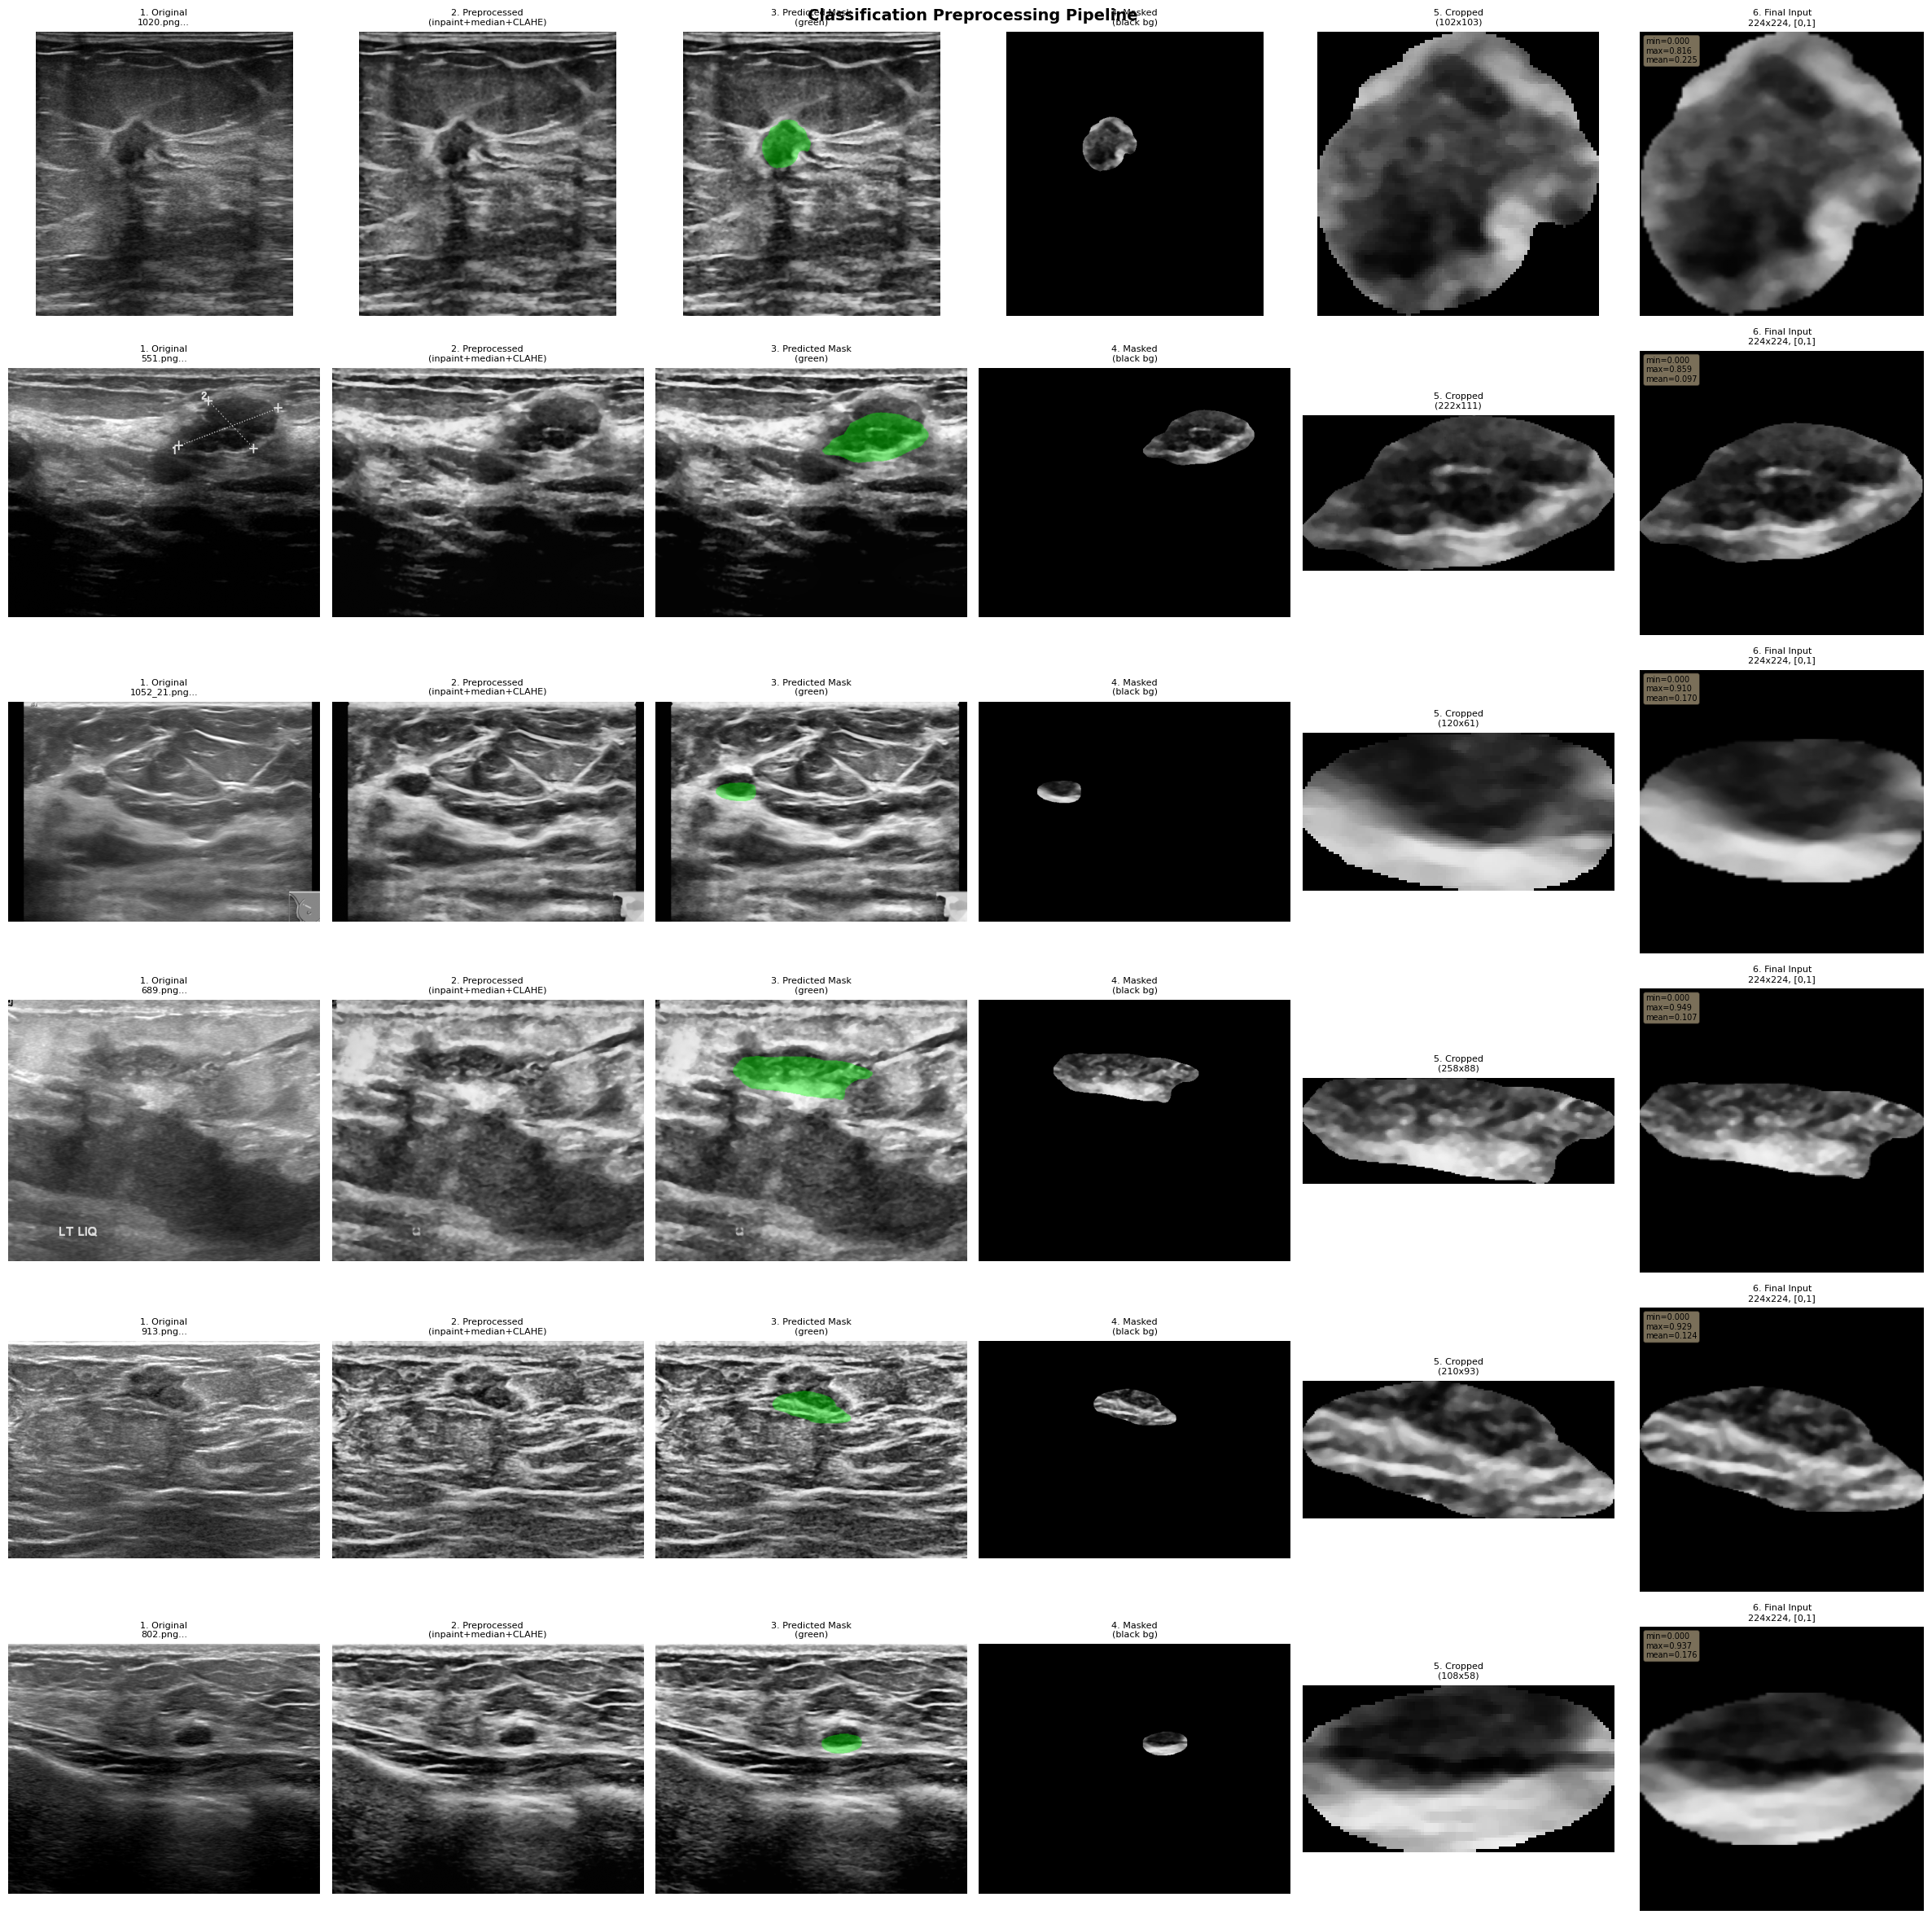


✅ Visualized 6 samples


In [25]:
samples_with_roi = [s for p in patients for s in p['samples'] if s['has_roi'] and s['classification_input'] is not None]
n_vis = min(6, len(samples_with_roi))
indices_to_show = np.random.choice(len(samples_with_roi), n_vis, replace=False)

fig, axes = plt.subplots(n_vis, 6, figsize=(24, 4*n_vis))
if n_vis == 1:
    axes = axes.reshape(1, -1)

for i, idx in enumerate(indices_to_show):
    sample = samples_with_roi[idx]
    
    # 1. Original
    img_bgr = cv2.imread(sample['img_path'])
    img_gray_orig = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    axes[i, 0].imshow(img_gray_orig, cmap='gray')
    axes[i, 0].set_title(f'1. Original\n{Path(sample["img_name"]).name[:20]}...', fontsize=8)
    axes[i, 0].axis('off')
    
    # 2. Preprocessed
    img_preprocessed = sample['preprocessed']
    axes[i, 1].imshow(img_preprocessed, cmap='gray', vmin=0, vmax=255)
    axes[i, 1].set_title('2. Preprocessed\n(inpaint+median+CLAHE)', fontsize=8)
    axes[i, 1].axis('off')
    
    # 3. Predicted mask overlay
    img_display = ((img_preprocessed - img_preprocessed.min()) / (img_preprocessed.max() - img_preprocessed.min() + 1e-8) * 255).astype(np.uint8)
    img_rgb = cv2.cvtColor(img_display, cv2.COLOR_GRAY2RGB)
    pred_mask_512 = sample['pred_mask_512']
    h_orig, w_orig = img_gray_orig.shape
    pred_mask_resized = cv2.resize(pred_mask_512, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
    mask_overlay = img_rgb.copy()
    mask_overlay[pred_mask_resized > 127] = [0, 255, 0]
    mask_overlay = cv2.addWeighted(img_rgb, 0.6, mask_overlay, 0.4, 0)
    axes[i, 2].imshow(mask_overlay)
    axes[i, 2].set_title('3. Predicted Mask\n(green)', fontsize=8)
    axes[i, 2].axis('off')
    
    # 4. Masked image
    masked_img = sample['masked']
    axes[i, 3].imshow(masked_img, cmap='gray', vmin=0, vmax=255)
    axes[i, 3].set_title('4. Masked\n(black bg)', fontsize=8)
    axes[i, 3].axis('off')
    
    # 5. Cropped
    if ConfigClassification.MASK_DILATION_PX > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ConfigClassification.MASK_DILATION_PX*2+1, ConfigClassification.MASK_DILATION_PX*2+1))
        mask_dilated = cv2.dilate(pred_mask_resized, kernel, iterations=1)
    else:
        mask_dilated = pred_mask_resized
    
    coords = np.where(mask_dilated > 0)
    if len(coords[0]) > 0:
        y_min, y_max = coords[0].min(), coords[0].max()
        x_min, x_max = coords[1].min(), coords[1].max()
        cropped_view = masked_img[y_min:y_max+1, x_min:x_max+1]
        axes[i, 4].imshow(cropped_view, cmap='gray', vmin=0, vmax=255)
        axes[i, 4].set_title(f'5. Cropped\n({cropped_view.shape[1]}x{cropped_view.shape[0]})', fontsize=8)
        axes[i, 4].axis('off')
    
    # 6. Final input
    final_input = sample['classification_input'][0].cpu().numpy()
    axes[i, 5].imshow(final_input, cmap='gray', vmin=0, vmax=1)
    axes[i, 5].set_title('6. Final Input\n224x224, [0,1]', fontsize=8)
    axes[i, 5].axis('off')
    
    stats_text = f'min={final_input.min():.3f}\nmax={final_input.max():.3f}\nmean={final_input.mean():.3f}'
    axes[i, 5].text(0.02, 0.98, stats_text, transform=axes[i, 5].transAxes,
                    fontsize=7, verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.suptitle('Classification Preprocessing Pipeline', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n✅ Visualized {n_vis} samples")

## Step 3: Classification Inference

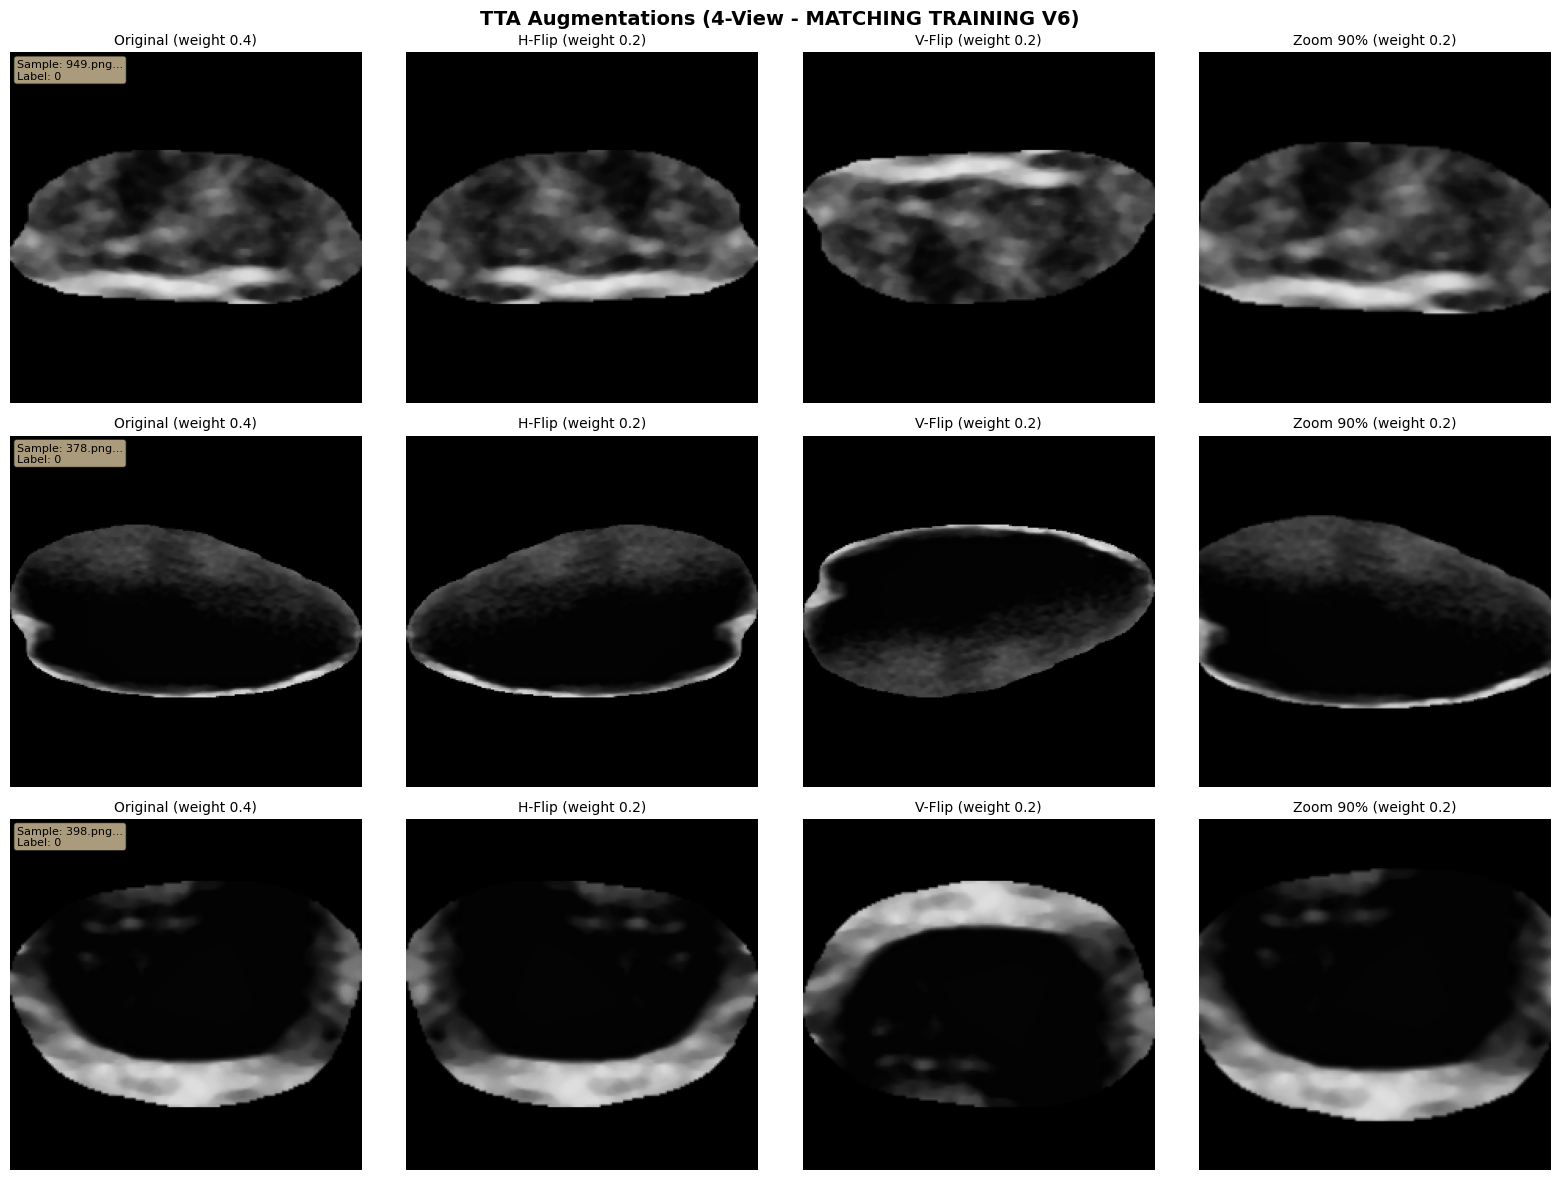


✅ Visualized 3 samples with TTA augmentations
   TTA Views: Original (0.4) + H-Flip (0.2) + V-Flip (0.2) + Zoom 90% (0.2)
   Weighted average → Ensemble → Final prediction


In [26]:
samples_with_roi = [s for p in patients for s in p['samples'] if s['has_roi'] and s['classification_input'] is not None]

if len(samples_with_roi) > 0:
    n_vis = min(3, len(samples_with_roi))
    indices_to_show = np.random.choice(len(samples_with_roi), n_vis, replace=False)
    
    fig, axes = plt.subplots(n_vis, 4, figsize=(16, 4*n_vis))
    if n_vis == 1:
        axes = axes.reshape(1, -1)
    
    for i, idx in enumerate(indices_to_show):
        sample = samples_with_roi[idx]
        img_tensor = sample['classification_input'].unsqueeze(0)  # (1, 3, 224, 224)
        
        img_single = img_tensor[0, 0].cpu().numpy()  # (224, 224)
        
        img = img_tensor.to(ConfigClassification.DEVICE)
        h, w = img.shape[2], img.shape[3]
        
        # 1. Original
        img_orig = img[0, 0].cpu().numpy()
        
        # 2. Horizontal Flip
        img_hflip = torch.flip(img, dims=[3])[0, 0].cpu().numpy()
        
        # 3. Vertical Flip
        img_vflip = torch.flip(img, dims=[2])[0, 0].cpu().numpy()
        
        # 4. Zoom 90%
        crop_size = int(h * 0.9)
        start = (h - crop_size) // 2
        img_cropped = img[:, :, start:start+crop_size, start:start+crop_size]
        img_zoom = F.interpolate(img_cropped, size=(h, w), mode='bilinear', align_corners=False)
        img_zoom = img_zoom[0, 0].cpu().numpy()
        
        # Display all 4 views
        views = [img_orig, img_hflip, img_vflip, img_zoom]
        titles = ['Original (weight 0.4)', 'H-Flip (weight 0.2)', 'V-Flip (weight 0.2)', 'Zoom 90% (weight 0.2)']
        
        for j, (view, title) in enumerate(zip(views, titles)):
            axes[i, j].imshow(view, cmap='gray', vmin=0, vmax=1)
            axes[i, j].set_title(title, fontsize=10)
            axes[i, j].axis('off')
            
            if j == 0:
                info_text = f'Sample: {Path(sample["img_name"]).name[:15]}...\nLabel: {sample["label"]}'
                axes[i, j].text(0.02, 0.98, info_text, transform=axes[i, j].transAxes,
                               fontsize=8, verticalalignment='top',
                               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))
    
    plt.suptitle('TTA Augmentations (4-View - MATCHING TRAINING V6)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print(f"\n✅ Visualized {n_vis} samples with TTA augmentations")
    print(f"   TTA Views: Original (0.4) + H-Flip (0.2) + V-Flip (0.2) + Zoom 90% (0.2)")
    print(f"   Weighted average → Ensemble → Final prediction")
else:
    print("⚠️ No samples with ROI available for visualization")

## Visualize TTA Augmentations

In [27]:
clf_weights_dir = Path(ConfigClassification.WEIGHTS_PATH)
clf_weight_files = sorted(clf_weights_dir.glob('*.pt'))

if len(clf_weight_files) == 0:
    raise FileNotFoundError(f"❌ ERROR: No .pt files found in {ConfigClassification.WEIGHTS_PATH}")

print(f"✅ Found {len(clf_weight_files)} classification model weights")

clf_models = []
for weights_file in clf_weight_files:
    model = EfficientNetWithROIAwareCBAM(num_classes=2).to(ConfigClassification.DEVICE)
    model.eval()
    
    try:
        checkpoint = torch.load(weights_file, map_location=ConfigClassification.DEVICE, weights_only=False)
        if 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'], strict=False)
        else:
            model.load_state_dict(checkpoint, strict=False)
        clf_models.append(model)
        print(f"✅ Loaded {weights_file.name}")
    except Exception as e:
        print(f"⚠️ Failed to load {weights_file.name}: {e}")

if len(clf_models) == 0:
    raise RuntimeError("❌ No classification models loaded!")

print(f"\\n✅ Loaded {len(clf_models)} models for ensemble\\n")

def apply_tta_ensemble(img_tensor, models, device, use_tta=True):
    if not use_tta:

        with torch.no_grad():
            all_probs = []
            for model in models:
                logits = model(img_tensor.to(device))
                probs = F.softmax(logits, dim=1)
                all_probs.append(probs)
            return torch.mean(torch.stack(all_probs), dim=0)
    

    tta_weights = [0.4, 0.2, 0.2, 0.2]  # [orig, hflip, vflip, zoom]
    

    img = img_tensor.to(device)
    b, c, h, w = img.shape
    
    # 1. Original
    imgs_orig = img
    
    # 2. Horizontal Flip
    imgs_hflip = torch.flip(img, dims=[3])
    
    # 3. Vertical Flip
    imgs_vflip = torch.flip(img, dims=[2])
    
    # 4. Zoom (center crop 90% + resize back)
    crop_size = int(h * 0.9)
    start = (h - crop_size) // 2
    imgs_cropped = img[:, :, start:start+crop_size, start:start+crop_size]
    imgs_zoom = F.interpolate(imgs_cropped, size=(h, w), mode='bilinear', align_corners=False)
    
    # Stack all TTA views: (4*B, C, H, W)
    tta_batch = torch.cat([imgs_orig, imgs_hflip, imgs_vflip, imgs_zoom], dim=0)
    
    # Ensemble + TTA
    with torch.no_grad():
        ensemble_probs = torch.zeros(b, ConfigClassification.NUM_CLASSES, device=device)
        
        for model in models:
            # Forward pass on all TTA views
            logits = model(tta_batch)
            probs = F.softmax(logits, dim=1)  # (4*B, num_classes)
            
            # Split by TTA view
            p_orig = probs[0:b]
            p_hflip = probs[b:2*b]
            p_vflip = probs[2*b:3*b]
            p_zoom = probs[3*b:4*b]
            
            # TTA weighted average
            model_avg = (p_orig * tta_weights[0] + 
                        p_hflip * tta_weights[1] + 
                        p_vflip * tta_weights[2] + 
                        p_zoom * tta_weights[3])
            
            ensemble_probs += model_avg
        
        # Ensemble mean
        final_probs = ensemble_probs / len(models)
    
    return final_probs


# Run inference on all images
print(f"{'='*80}")
print(f"🔬 CLASSIFICATION INFERENCE (TTA + Ensemble - MATCHING TRAINING)")
print(f"   TTA: 4-View (Original 0.4, H-Flip 0.2, V-Flip 0.2, Zoom 90% 0.2)")
print(f"   Ensemble: {len(clf_models)} models (soft voting)")
print(f"   Decision: argmax (threshold 0.5)")
print(f"{'='*80}\\n")

with torch.no_grad():
    for patient in tqdm(patients, desc="Classification inference"):
        for sample in patient['samples']:
            if sample['classification_input'] is None:
                # Already marked as normal (no ROI or invalid mask)
                sample['prob_benign'] = 0.0
                sample['prob_malignant'] = 0.0
                continue
            
            img_tensor = sample['classification_input'].unsqueeze(0)
            
            probs = apply_tta_ensemble(img_tensor, clf_models, ConfigClassification.DEVICE, use_tta=True)
            probs = probs[0].cpu().numpy()
            
            sample['pred_class'] = np.argmax(probs)
            sample['prob_benign'] = float(probs[0])
            sample['prob_malignant'] = float(probs[1])

# Aggregate predictions per patient (majority voting)
print(f"\\n{'='*80}")
print(f"🔬 PATIENT-LEVEL AGGREGATION (Majority Voting)")
print(f"{'='*80}\\n")

for patient in patients:
    pred_classes = [s['pred_class'] for s in patient['samples']]
    
    # Majority voting
    patient['pred_label'] = int(np.argmax(np.bincount(pred_classes)))
    
    # Average probabilities
    patient['avg_prob_benign'] = np.mean([s['prob_benign'] for s in patient['samples']])
    patient['avg_prob_malignant'] = np.mean([s['prob_malignant'] for s in patient['samples']])

print(f"✅ Classification complete:")
print(f"   Total patients: {len(patients)}")
print(f"   Patient predictions:")
print(f"     Benign (0): {sum(1 for p in patients if p['pred_label'] == 0)}")
print(f"     Malignant (1): {sum(1 for p in patients if p['pred_label'] == 1)}")
print(f"     Normal (2): {sum(1 for p in patients if p['pred_label'] == 2)}")
print(f"{'='*80}\\n")

✅ Found 5 classification model weights


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

✅ Loaded best_classification_fold0 (2).pt
✅ Loaded best_classification_fold1 (1).pt
✅ Loaded best_classification_fold2 (1).pt
✅ Loaded best_classification_fold3 (1).pt
✅ Loaded best_classification_fold4 (1).pt
\n✅ Loaded 5 models for ensemble\n
🔬 CLASSIFICATION INFERENCE (TTA + Ensemble - MATCHING TRAINING)
   TTA: 4-View (Original 0.4, H-Flip 0.2, V-Flip 0.2, Zoom 90% 0.2)
   Ensemble: 5 models (soft voting)
   Decision: argmax (threshold 0.5)
================================================================================\n


Classification inference:   0%|          | 0/194 [00:00<?, ?it/s]

\n================================================================================
🔬 PATIENT-LEVEL AGGREGATION (Majority Voting)
================================================================================\n
✅ Classification complete:
   Total patients: 194
   Patient predictions:
     Benign (0): 127
     Malignant (1): 39
     Normal (2): 28
================================================================================\n


## Step 4: Calculate Metrics (Dice + Balanced Accuracy)

In [28]:
print(f"\\n{'='*80}")
print(f"📊 METRICS CALCULATION")
print(f"{'='*80}\\n")

print("🎯 DICE SCORE (Segmentation Quality)\\n")

dice_scores = []

for patient in patients:
    for sample in patient['samples']:
        pred_mask_512 = sample['pred_mask_512']
        gt_mask = sample['gt_mask']
        
        h_gt, w_gt = gt_mask.shape
        pred_mask_resized = cv2.resize(pred_mask_512, (w_gt, h_gt), interpolation=cv2.INTER_NEAREST)
        
        pred_binary = (pred_mask_resized > 0).astype(int).flatten()
        gt_binary = (gt_mask > 0).astype(int).flatten()
        
        f1 = f1_score(gt_binary, pred_binary, zero_division=0)
        dice_scores.append(f1)

mean_dice = np.mean(dice_scores)
print(f"✅ DICE SCORE: {mean_dice:.4f}")
print(f"   Total images: {len(dice_scores)}")
print(f"   Min: {np.min(dice_scores):.4f}, Max: {np.max(dice_scores):.4f}, Std: {np.std(dice_scores):.4f}\\n")

print(f"\\n{'='*80}")
print("📊 BALANCED ACCURACY (2-CLASS: Benign vs Malignant)")
print(f"{'='*80}\\n")

patients_2class = [p for p in patients if p['major_label'] in [0, 1]]

if len(patients_2class) > 0:
    gt_2class = [p['major_label'] for p in patients_2class]
    pred_2class = [p['pred_label'] for p in patients_2class]
    
    ba_2class = balanced_accuracy_score(gt_2class, pred_2class)
    cm_2class = confusion_matrix(gt_2class, pred_2class)
    
    print(f"Patients evaluated: {len(patients_2class)}")
    print(f"  Ground Truth - Benign: {gt_2class.count(0)}, Malignant: {gt_2class.count(1)}")
    print(f"  Predictions - Benign: {pred_2class.count(0)}, Malignant: {pred_2class.count(1)}")
    print(f"\\n✅ BALANCED ACCURACY: {ba_2class:.4f}")
    print(f"\\nConfusion Matrix:")
    print(cm_2class)
else:
    ba_2class = None
    print("⚠️ No 2-class patients available")

print(f"\\n\\n{'='*80}")
print("📊 BALANCED ACCURACY (3-CLASS: Benign vs Malignant vs Normal)")
print(f"{'='*80}\\n")

gt_3class = [p['major_label'] for p in patients]
pred_3class = [p['pred_label'] for p in patients]

ba_3class = balanced_accuracy_score(gt_3class, pred_3class)
cm_3class = confusion_matrix(gt_3class, pred_3class)

print(f"Patients evaluated: {len(patients)}")
print(f"  Ground Truth - Benign: {gt_3class.count(0)}, Malignant: {gt_3class.count(1)}, Normal: {gt_3class.count(2)}")
print(f"  Predictions - Benign: {pred_3class.count(0)}, Malignant: {pred_3class.count(1)}, Normal: {pred_3class.count(2)}")
print(f"\\n✅ BALANCED ACCURACY: {ba_3class:.4f}")
print(f"\\nConfusion Matrix:")
print(cm_3class)

print(f"\\n\\n{'='*80}")
print("📋 FINAL SUMMARY")
print(f"{'='*80}")
print(f"Dice Score (Segmentation): {mean_dice:.4f}")
if ba_2class is not None:
    print(f"2-Class BA (Benign vs Malignant): {ba_2class:.4f}")
print(f"3-Class BA (All classes): {ba_3class:.4f}")
print(f"{'='*80}")

\n================================================================================
📊 METRICS CALCULATION
================================================================================\n
🎯 DICE SCORE (Segmentation Quality)\n
✅ DICE SCORE: 0.3694
   Total images: 308
   Min: 0.0000, Max: 0.9485, Std: 0.3572\n
\n================================================================================
📊 BALANCED ACCURACY (2-CLASS: Benign vs Malignant)
================================================================================\n
Patients evaluated: 165
  Ground Truth - Benign: 108, Malignant: 57
  Predictions - Benign: 123, Malignant: 36
\n✅ BALANCED ACCURACY: 0.6854
\nConfusion Matrix:
[[95  8  5]
 [28 28  1]
 [ 0  0  0]]
\n\n================================================================================
📊 BALANCED ACCURACY (3-CLASS: Benign vs Malignant vs Normal)
================================================================================\n
Patients evaluated: 194
  Ground Truth - Beni

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
